#### Data & Set up 

In [60]:
# Upload libraries 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import rioxarray as rioxr
import matplotlib.patches as mpatches


In [2]:
# Upload Easton fire and Palisides fire paremeters

fp = os.path.join('data','Eaton_Perimeter_20250121','Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp)


fp = os.path.join('data','Palisades_Perimieter_20250121','Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp)

#### 2. Fire perimeter data exploration

Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic. 

In [3]:
eaton.plot()

<Axes: >

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

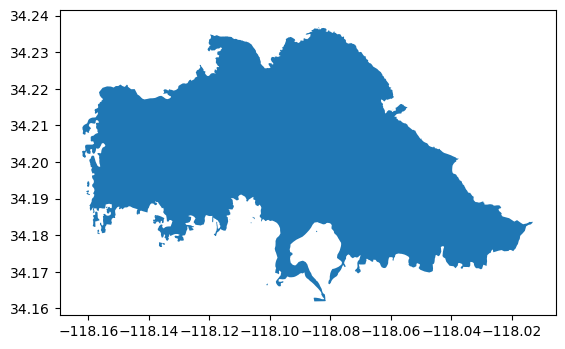

In [4]:
eaton.crs

In [5]:
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

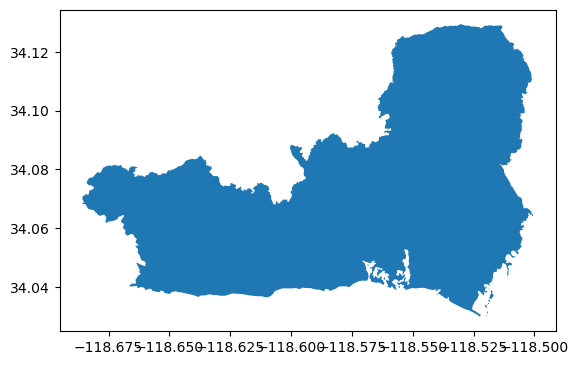

In [6]:
palisades.plot()

#### 3. NetCDF data import and exploration

a. Import the Landsat data using `xr.open_dataset()`

In [7]:
# Import NIR TIF file

fp = os.path.join("data/landsat8-2025-02-23-palisades-eaton.nc")
lsat8 = xr.open_dataset(fp)
lsat8

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

b. Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data's variables, dimensions, and coordinates.

In [8]:
lsat8.rio.shape

(1418, 2742)

In [9]:
lsat8.plot

#### 4. Restoring geospatial information

a. Use `rio.crs` to print the CRS of this dataset. Is this a geospatial object?

In [10]:
print("CRS:",lsat8.rio.crs)

CRS: None


b. You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable `spatial_ref`. Print the CRS by accessing the `spatial_ref.crs_wkt` attribute of the dataset.

In [11]:
print(lsat8.spatial_ref.crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


c. Recover the geospatial information by using [`rio.write_crs()`](https://vylor.github.io/rioxarray/stable/getting_started/crs_management.html#Setting-the-CRS) and the spatial reference information from part b. 

In [12]:
lsat8 = lsat8.rio.write_crs("EPSG:32611", inplace=True)

d. Print the CRS of the updated dataset. 

In [13]:
print(lsat8.rio.crs)
print(lsat8.spatial_ref.crs_wkt)


EPSG:32611
PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


#### 5. True color image

a. Without creating any new variables: 
  - select the red, green, and blue variables (in that order) of the `xarray.Dataset` holding the Landsat data, 
  - convert it to an `xarray.DataArray` using the [`to_dataarray()`](https://docs.xarray.dev/en/stable/generated/xarray.Dataset.to_dataarray.html) method, and then 
  - use `.plot.imshow()` to create an RGB image with the data. 
There will be a warning; that's ok.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


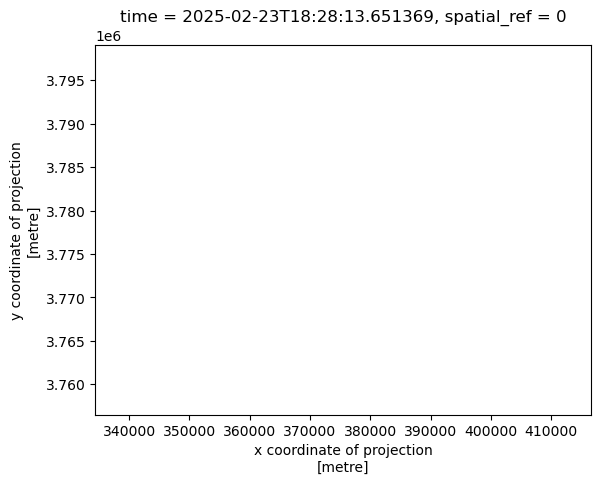

In [14]:
lsat8[["red", "green", "blue"]].to_dataarray().plot.imshow()

b. Adjust the scale used for plotting the bands to get a true color image. 
HINT: [Check the `robust` parameter](https://docs.xarray.dev/en/stable/generated/xarray.plot.imshow.html). 

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


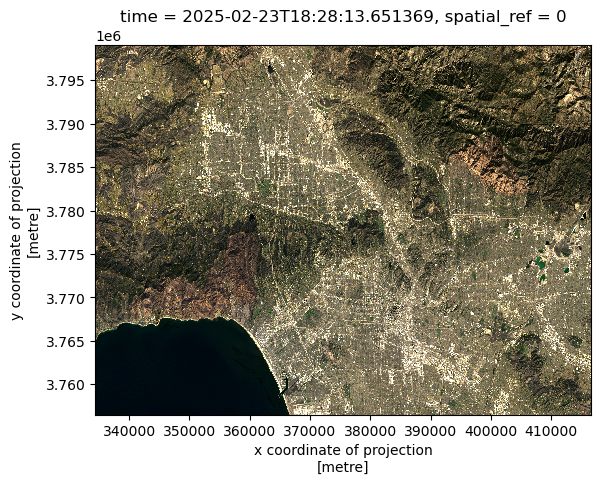

In [15]:
lsat8[["red", "green", "blue"]].to_dataarray().plot.imshow(robust=True)

<!-- The issue here is the clouds: their RGB values are outliers and cause the other values to be squished when plotting.  -->

c. To resolve the other warning, identify which bands have `nan` values. HINT: There are many ways of doing so. One option is to use [`numpy.isnan()`](https://numpy.org/devdocs/reference/generated/numpy.isnan.html).

In [17]:
np.isnan(lsat8)

<xarray.Dataset> Size: 19MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) bool 4MB False False False False ... False False False
    green        (y, x) bool 4MB False False False False ... False False False
    blue         (y, x) bool 4MB False False False False ... False False False
    nir08        (y, x) bool 4MB False False False False ... False False False
    swir22       (y, x) bool 4MB False False False False ... False False False

d. Use the [`.fillna()`](https://docs.xarray.dev/en/latest/generated/xarray.Dataset.fillna.html) method for `xarray.Dataset`s to replace any `nan` values in the Landsat data with zero. 

In [19]:
lsat8.fillna(0)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB 1.024e+04 9.886e+03 ... 1.019e+04 9.967e+03
    green        (y, x) float32 16MB 9.93e+03 9.687e+03 ... 9.984e+03 9.662e+03
    blue         (y, x) float32 16MB 9.29e+03 9.183e+03 ... 9.49e+03 9.187e+03
    nir08        (y, x) float32 16MB 1.331e+04 1.313e+04 ... 1.287e+04 1.306e+04
    swir22       (y, x) float32 16MB 1.43e+04 1.437e+04 ... 1.406e+04 1.329e+04

e. Create a new true color image that gets plotted without warnings. 

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


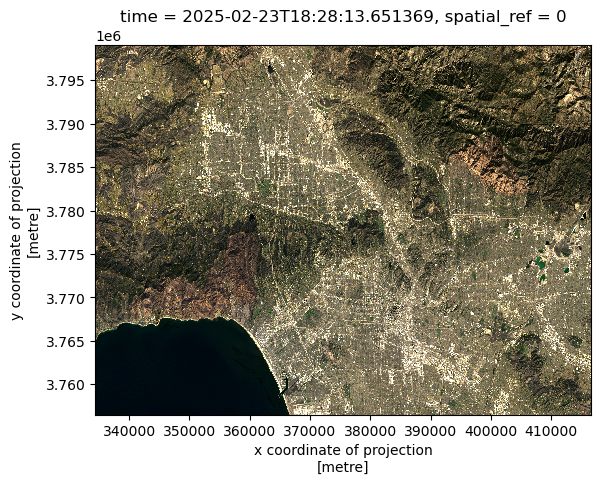

In [21]:
lsat8[["red", "green", "blue"]].to_dataarray().plot.imshow(robust=True)

f. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e). 

#### 6. False color image
Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order). 

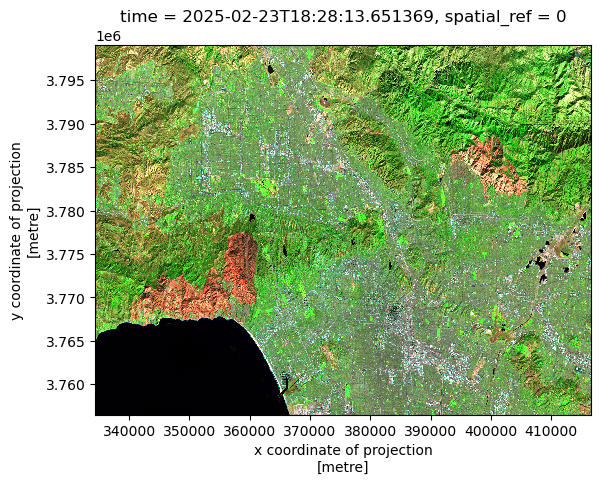

In [ ]:
lsat8[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(robust=True)

#### 7. Map

a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire _perimeters_. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

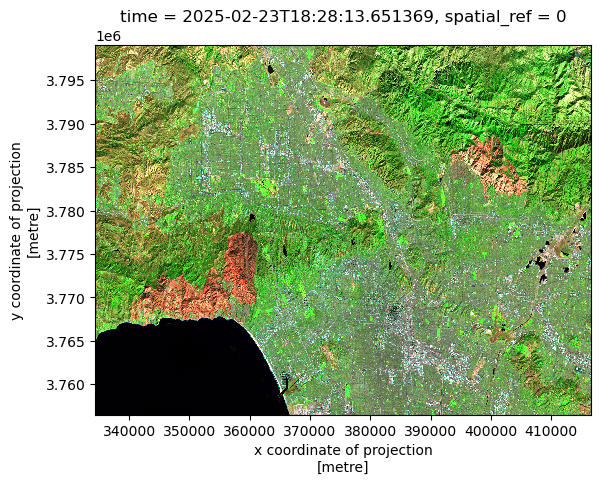

In [ ]:
lsat8[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(robust=True)



b. Write a figure description for the map including a brief explanation of how false color imagery is being used.

Text(0, 0.5, '')

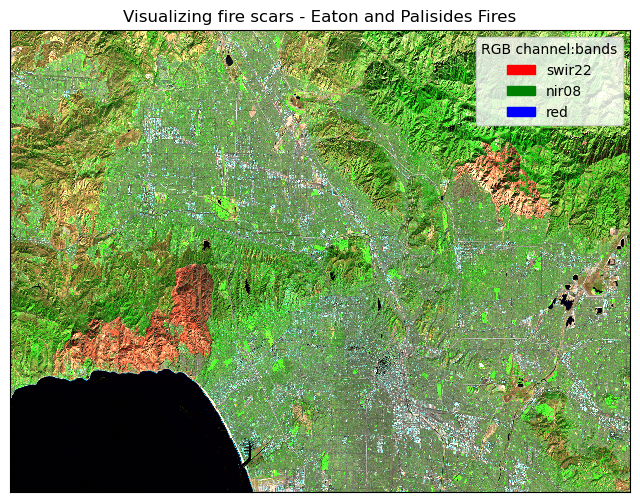

In [72]:
fig, ax = plt.subplots(figsize=(8, 6))
lsat8[["swir22", "nir08", "red"]].to_dataarray().squeeze().plot.imshow(robust=True, ax=ax)
ax.set_title("Visualizing fire scars - Eaton and Palisides Fires")


band_legend = ax.legend(handles=[
    mpatches.Patch(color="red",   label="swir22"),
    mpatches.Patch(color="green", label="nir08"),
    mpatches.Patch(color="blue",  label="red"),
], title="RGB channel:bands", loc="upper right")

# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

:::{.callout-caution appearance="minimal"}
The rest of the sections are about updating and cleaning your notebooks and repository. **This is hugely important!** By maintaining clean, well-structured repositories and notebooks, you’re not only showcasing your technical skills but also building a portfolio that reflects your professionalism, attention to detail, and ability to collaborate effectively with others.

Here is an [example of an organized repository and notebook](https://github.com/carmengg/eds220-oil-spills-sample-repo) based on the oil spills task from homework 3. 
:::

#### 8. Clean your notebooks

The target audience for your notebooks is a fellow EDS 220 student who is just learning about wrangling raster data using Python. 

- Add enough and appropriate comments to explain your code.
- Add enough and appropriate markdown cells to explain the procedures you are using and their output.
- The first cell in the notebook must be a markdown cell including: 
  - [ ] Title
  - [ ] Author
  - [ ] Link to GitHub repository containing the notebook (for grading purposes)
- Each notebook must include an "About" section with the following subsections: 
    - [ ] Purpose: what is this notebook about?
    - [ ] Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most important aspects of this coding exercise?
    - [ ] About the data: Datasets description
    - [ ] References: Formal references to datasets. You can use the APA style as outlined [here](https://library.cumc.columbia.edu/insight/citing-data-sources).

The rest of your notebook should be organized into logical subsections (indicated through markdown headers) for the analysis and visualization you are performing. The subsections should easily guide the reader through the analysis.


#### 9. Update your repository {#sec-repo-instructions}

- [ ] **Title.** Short, but descriptive title.
- [ ] **"About" section.** A brief explanation of the repository’s purpose.
  Paragraphs or a bulleted list are both acceptable options. 
  You may include an image or logo that represents the project.
- [ ] **"Repository Structure" section.** A concise description of what’s housed in the repository.
  This includes information about the repository structure or file organization.
- [ ] **"Data" section.** Details regarding data access. Any necessary information on where data lives (e.g. is it housed in the repo, on a server, in a library / package etc.) and how to access it in order to run the code. 
- [ ] **"References" section.** In an appropriate, consistent format, including links, provide a reference to the course and any other sources that supported the development of the repository. **Include formal references to the datasets.** You can use the APA style to cite data sources as outlined [here](https://library.cumc.columbia.edu/insight/citing-data-sources).